<a href="https://colab.research.google.com/github/michellecarizona/pandas-practice-2/blob/main/pandas_hw_practice_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pandas Advanced Practice for Data Science

A one-hour hands-on tour of the *most useful* advanced Pandas skills:

1. **Group & Aggregate** — answer "per group" questions
2. **Concatenate & Merge** — combine several tables
3. **Remove duplicates & bin values** — clean data
4. **Pivot & Crosstab** — reshape data
5. **Visualize** — turn tables into charts
6. **Time-Series** — work with dates, resampling, and rolling windows

- **Duration:** ~1 hour
- **Platform:** Google Colab (no setup needed)
- **How to use it:** Type each cell along with the instructor. Press `Shift + Enter` to run a cell.

In [ ]:
# Import pandas (data tables) with the standard nickname 'pd'
import pandas as pd
# Import numpy (numbers) with the standard nickname 'np'
import numpy as np
# Import matplotlib for plotting, with the standard nickname 'plt'
import matplotlib.pyplot as plt
# Import seaborn — includes built-in datasets and nicer default plot styling
import seaborn as sns
# Turn on a clean dark-grid look for all our plots
sns.set_style("darkgrid")

Imports all required libraries (pandas, numpy, matplotlib, seaborn)

## 1. Setup

We use `pandas` for tables, `numpy` for numbers, `matplotlib` for plots, and `seaborn` for its built-in practice datasets (Titanic, flights, tips).

In [ ]:
# Load the built-in Titanic dataset — each row is one passenger
titanic_data = sns.load_dataset('titanic')
# Preview the first 5 rows
titanic_data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Loads the built-in Seaborn Titanic dataset into a Pandas DataFrame and previews the first 5 rows to inspect its columns.

In [ ]:
# Group the Titanic dataset by the 'class' column (First, Second, Third)
# observed=False keeps the current behavior and silences a warning
by_class = titanic_data.groupby("class", observed=False)
# .size() tells us how many passengers are in each group
by_class.size()

,0
class,
First,216
Second,184
Third,491


Groups the passenger data by passenger class (First, Second, Third) and counts how many passengers belong to each group using .size().

In [ ]:
# Get the maximum age from each class
# Shorthand: after groupby, we can pick a column with .age or ['age']
by_class.age.max()

,age
class,
First,80.0
Second,70.0
Third,74.0


Extracts the age column from each grouped category and finds the maximum age for each passenger class.

## 2. Group & Aggregate with `groupby`

Question: *"What was the average fare in each passenger class?"* — that's a **per-group** question. We use `groupby` to answer it.

In [ ]:
# Run SEVERAL statistics at once on the 'fare' column using .agg([...])
by_class.fare.agg(['max', 'min', 'count', 'median', 'mean'])

,max,min,count,median,mean
class,,,,,
First,512.3292,0.0,216,60.2875,84.154687
Second,73.5000,0.0,184,14.2500,20.662183
Third,69.5500,0.0,491,8.0500,13.675550


Applies multiple summary statistics simultaneously (max, min, count, median, mean) to the fare column for each class group using .agg().

In [ ]:
# We can group by MORE than one column — here: class AND sex
# The result has one row per (class, sex) combination
titanic_data.groupby(["class", "sex"], observed=False)["fare"].mean()

class   sex   
First   female    106.125798
        male       67.226127
Second  female     21.970121
        male       19.741782
Third   female     16.118810
        male       12.661633
Name: fare, dtype: float64

Filters the main dataset into two separate subsets (First Class and Second Class) and prints their row/column dimensions.

Demonstrates multi-column grouping by grouping simultaneously on both class and sex, then calculating the mean fare for each unique combination.

In [ ]:
# Filter passengers into two smaller DataFrames — one per class
first_class  = titanic_data[titanic_data["class"] == "First"]
second_class = titanic_data[titanic_data["class"] == "Second"]
# Show the shape (rows, columns) of each — First has 216, Second has 184
print("first:",  first_class.shape)
print("second:", second_class.shape)

first: (216, 15)
second: (184, 15)


Filters the main dataset into two separate subsets (First Class and Second Class) and prints their row/column dimensions.

In [ ]:
  # pd.concat stacks the tables on top of each other (216 + 184 = 400 rows)
# ignore_index=True renumbers rows so we don't have duplicate labels
combined = pd.concat([first_class, second_class], ignore_index=True)
print(combined.shape)

(400, 15)


Combines the two separate dataframes back into a single table by stacking them vertically with pd.concat, resetting the row indices.

In [ ]:
# Build two small demo DataFrames to practice merging
# Both share the 'Subject' column — that's the KEY we'll match on
scores1_df = pd.DataFrame([
    {'Subject': 'Mathematics', 'Score': 85},
    {'Subject': 'History',     'Score': 98},
    {'Subject': 'English',     'Score': 76},
    {'Subject': 'Chemistry',   'Score': 72},
])
scores2_df = pd.DataFrame([
    {'Subject': 'Arts',        'Grade': 'C'},
    {'Subject': 'Physics',     'Grade': 'C'},
    {'Subject': 'English',     'Grade': 'A'},
    {'Subject': 'Chemistry',   'Grade': 'A'},
])
print(scores1_df)
print(scores2_df)

       Subject  Score
0  Mathematics     85
1      History     98
2      English     76
3    Chemistry     72
     Subject Grade
0       Arts     C
1    Physics     C
2    English     A
3  Chemistry     A


Run this to create two small dataframes from lists of Python dictionaries. Notice that both tables share a column named Subject. This shared column acts as the "key" we will use to link the tables together in the next steps.

## 3. Concatenate & Merge

- **Concatenate** = stack tables on top of (or beside) each other.
- **Merge** = combine two tables by matching values in a shared column (like SQL JOIN).

In [ ]:
# INNER merge — keep ONLY subjects that exist in BOTH tables
# Result: English + Chemistry (the two shared subjects)
scores1_df.merge(scores2_df, on='Subject', how='inner')

,Subject,Score,Grade
0,English,76,A
1,Chemistry,72,A


Use merge with how='inner' to return only the rows where the Subject exists in both tables simultaneously. Because only English and Chemistry appear in both scores1_df and scores2_df, the resulting table will only contain those two rows.

In [ ]:
# LEFT merge — keep ALL rows from the LEFT table, fill missing right-side values with NaN
scores1_df.merge(scores2_df, on='Subject', how='left')

,Subject,Score,Grade
0,Mathematics,85,NaN
1,History,98,NaN
2,English,76,A
3,Chemistry,72,A


Change the method to how='left'. This forces Pandas to keep every single row from the left table (scores1_df). If the right table (scores2_df) doesn't have a matching subject (like Mathematics or History), Pandas fills the missing Grade data with NaN (Not a Number).

In [ ]:
# OUTER merge — keep ALL rows from BOTH tables; missing values become NaN
scores1_df.merge(scores2_df, on='Subject', how='outer')

,Subject,Score,Grade
0,Arts,NaN,C
1,Chemistry,72.0,A
2,English,76.0,A
3,History,98.0,NaN
4,Mathematics,85.0,NaN
5,Physics,NaN,C


Use how='outer' to combine everything. This keeps all subjects from both tables regardless of whether they have a match. Missing scores for Arts/Physics and missing grades for Math/History will all be filled with NaN.

## 4. Removing Duplicates and Binning Values

In [ ]:
# Small demo DataFrame with two identical rows
scores = pd.DataFrame({
    'Subject': ['Math', 'English', 'History', 'History', 'Arts'],
    'Score':   [85, 91, 95, 95, 88],
})
scores

,Subject,Score
0,Math,85
1,English,91
2,History,95
3,History,95
4,Arts,88


Create a new test dataframe specifically to practice cleaning data. Note the deliberate mistake: the History row with a score of 95 appears twice.

In [ ]:
# drop_duplicates() removes exact duplicate rows (keeping the first by default)
scores.drop_duplicates()

,Subject,Score
0,Math,85
1,English,91
2,History,95
4,Arts,88


Run drop_duplicates(). By default, this function looks at every column in the row. If an entire row is exactly identical to a previous row, it deletes the duplicate. The second History row is removed.

In [ ]:
# We can also check duplicates only on specific columns
# subset=['Score'] means: treat rows as duplicates if their 'Score' is the same
scores.drop_duplicates(subset=['Score'])

,Subject,Score
0,Math,85
1,English,91
2,History,95
4,Arts,88


Add the subset parameter to instruct Pandas to check for duplicates based only on the values in the Score column. If two different subjects accidentally had the exact same score, this command would drop the second subject.

In [ ]:
# BINNING = turn continuous numbers into categories
# Here we group ages into 4 buckets: toddler, young, adult, senior
titanic_data['age_group'] = pd.cut(
    x=titanic_data['age'],                         # the number column to bin
    bins=[0, 5, 20, 60, 100],                        # the bucket edges
    labels=["toddler", "young", "adult", "senior"]   # names for each bucket
)
# Show how many passengers ended up in each age group
titanic_data['age_group'].value_counts()

,count
age_group,
adult,513
young,135
toddler,44
senior,22


Use pd.cut() to perform "binning," which converts continuous numerical data (ages like 2.5, 30, 45) into distinct categories. The bins list defines the exact numerical cutoffs for the edges of the buckets, and labels assigns the text name to each bucket. value_counts() then sums up how many people fell into each category.

## 5. Pivot Table & Crosstab

- **pivot_table** reshapes long data into a wide summary table.
- **crosstab** counts how often each combination of two categories appea

In [ ]:
# Load the built-in 'flights' dataset — passengers per month from 1949 to 1960
flights_data = sns.load_dataset('flights')
flights_data.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [ ]:
# Reshape flights into a grid: months as rows, years as columns, passengers as values
flights_pivot = flights_data.pivot_table(
    index='month',        # rows
    columns='year',       # columns
    values='passengers',  # what to put inside each cell
    observed=False
)
flights_pivot.head()

year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112.0,115.0,145.0,171.0,196.0,204.0,242.0,284.0,315.0,340.0,360.0,417.0
Feb,118.0,126.0,150.0,180.0,196.0,188.0,233.0,277.0,301.0,318.0,342.0,391.0
Mar,132.0,141.0,178.0,193.0,236.0,235.0,267.0,317.0,356.0,362.0,406.0,419.0
Apr,129.0,135.0,163.0,181.0,235.0,227.0,269.0,313.0,348.0,348.0,396.0,461.0
May,121.0,125.0,172.0,183.0,229.0,234.0,270.0,318.0,355.0,363.0,420.0,472.0


Load a new dataset, then use pivot_table to reshape the long list of data into a 2D matrix. index dictates what becomes the rows (months), columns dictates what spreads horizontally (years), and values dictates what populates the intersecting cells (passenger counts).

In [ ]:
# crosstab counts how many passengers of each SEX travelled in each CLASS
# margins=True adds a total 'All' row and column
pd.crosstab(titanic_data["class"], titanic_data["sex"], margins=True)

sex,female,male,All
class,,,
First,94,122,216
Second,76,108,184
Third,144,347,491
All,314,577,891


Use pd.crosstab() to create a frequency table that counts how many times specific combinations of categories occur (e.g., how many female passengers were in First class). Adding margins=True generates the "All" row and column to show total sums.

## 6. Visualisation with Pandas

Pandas has plotting built right in. Under the hood it uses Matplotlib, but the code is much shorter.

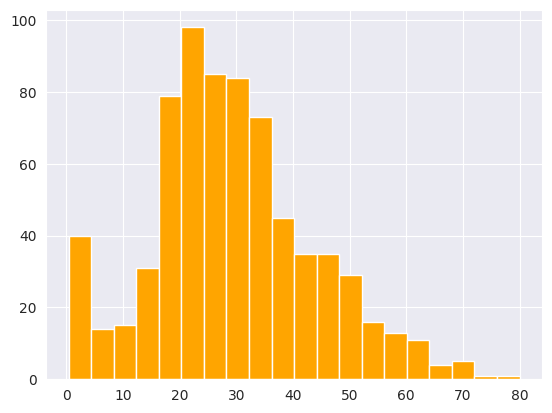

In [ ]:
# HISTOGRAM — shows the distribution of a numeric column
# bins=20 splits the data into 20 groups; color= sets the bar color
titanic_data['age'].hist(bins=20, color='orange')
# plt.show() forces the plot to display right now
plt.show()

Select the continuous age column and call .hist() to view its frequency distribution. The bins=20 argument splits the data range into 20 equal-width vertical bars. plt.show() renders the graph to the screen.

## 7. Time-Series Data

A **time series** is data that changes over time — think daily temperature, monthly sales, or stock prices.

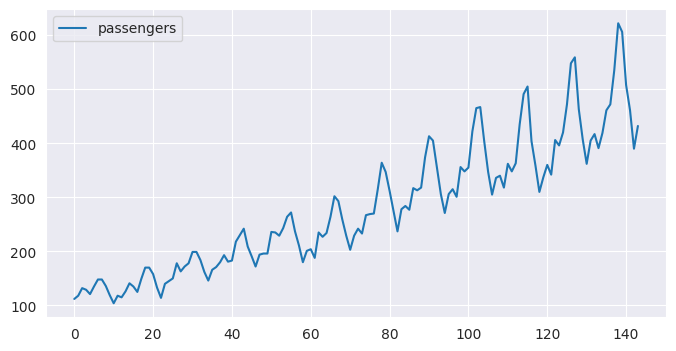

In [ ]:
# LINE plot — great for values that change over time
# figsize sets the width and height of the chart (in inches)
flights_data.plot.line(y='passengers', figsize=(8, 4))
plt.show()

Call .plot.line() to track the trend of passengers over time. The figsize=(8, 4) argument dictates the dimensions of the chart in inches (width, height).

### Real time-series: Google stock prices

We'll load real Google stock data from a URL — thousands of rows spanning almost 20 years.

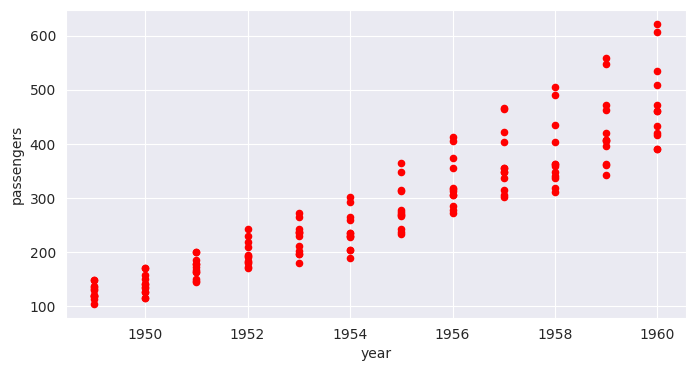

In [ ]:
# SCATTER plot — one dot per row; shows the relationship between two numeric columns
flights_data.plot.scatter(x='year', y='passengers', color='red', figsize=(8, 4))
plt.show()

Call .plot.scatter() to plot individual data points based on two numeric axes. This reveals the correlation between the passing years (x-axis) and the growing number of passengers (y-axis).

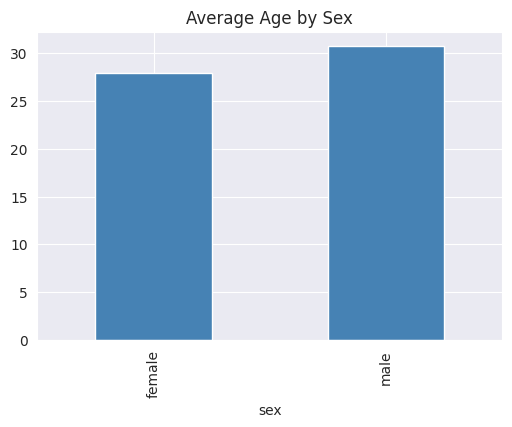

In [ ]:
# BAR chart — compare a number across a few categories
# Step 1: compute the average age for each sex
sex_mean = titanic_data.groupby("sex", observed=False)["age"].mean()
# Step 2: plot the resulting Series directly as a bar chart
sex_mean.plot(kind='bar', color='steelblue', title='Average Age by Sex', figsize=(6, 4))
plt.show()

First, chain a groupby() and .mean() to calculate a single average age for each sex. Then, chain .plot(kind='bar') directly onto that resulting data to generate a bar chart.

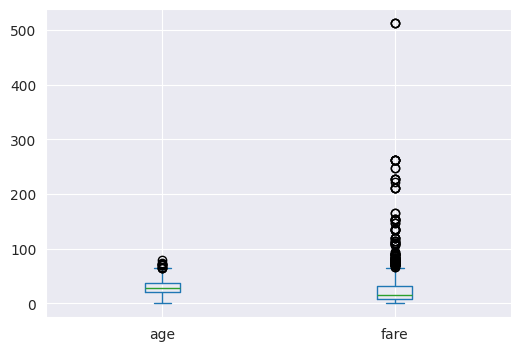

In [ ]:
# BOX plot — shows the spread (min, quartiles, max) of numeric columns
# 'age' and 'fare' are on very different scales, but the box plot still works
titanic_data[['age', 'fare']].plot.box(figsize=(6, 4))
plt.show()


Pass a list of columns ['age', 'fare'] into .plot.box(). This creates a statistical box plot for both variables side-by-side, visually marking the median line, the 25th/75th percentiles (the box), and outliers (dots outside the whiskers).

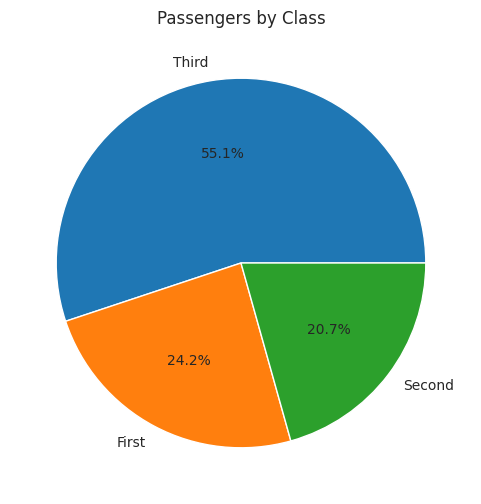

In [ ]:
# PIE chart — shows how a whole is split into parts
# autopct puts the percentage on each slice
titanic_data["class"].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',   # format the percentage label
    figsize=(6, 6),
    title='Passengers by Class'
)
plt.ylabel('')          # hide the extra 'class' label on the y-axis
plt.show()

Use value_counts() to get the raw counts for each class, then pipe that directly into .plot(kind='pie'). The autopct format string overlays the calculated percentage onto each slice. plt.ylabel('') removes the default axis text for a cleaner look.

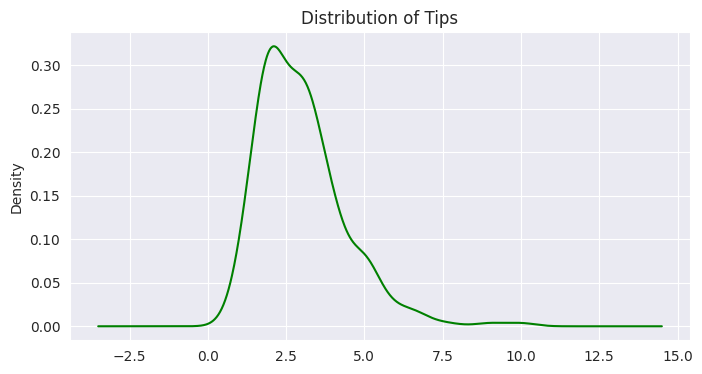

In [ ]:
# KDE plot (Kernel Density Estimate) — a smooth version of a histogram
# We use the built-in 'tips' dataset (restaurant tips)
tips_data = sns.load_dataset('tips')
tips_data['tip'].plot.kde(figsize=(8, 4), color='green', title='Distribution of Tips')
plt.show()

Load a new dataset to plot a Kernel Density Estimate (KDE). This visualizes the distribution of the tip column as a smooth, continuous curve rather than the jagged blocks of a standard histogram.

In [ ]:
# pd.date_range creates a list of dates — here every day from Jan 1 to Jun 30, 2021
dates = pd.date_range(start='2021-01-01', end='2021-06-30')
# Print how many dates were made
print(len(dates))

181


In [ ]:
# Build a small time-series DataFrame — dates + random temperatures
date_df = pd.DataFrame({'Date': dates})
# Add a random 'Temperature' column between 0 and 49 for every date
date_df['Temperature'] = np.random.randint(0, 50, size=len(dates))
date_df.head()

,Date,Temperature
0,2021-01-01,14
1,2021-01-02,35
2,2021-01-03,39
3,2021-01-04,31
4,2021-01-05,32


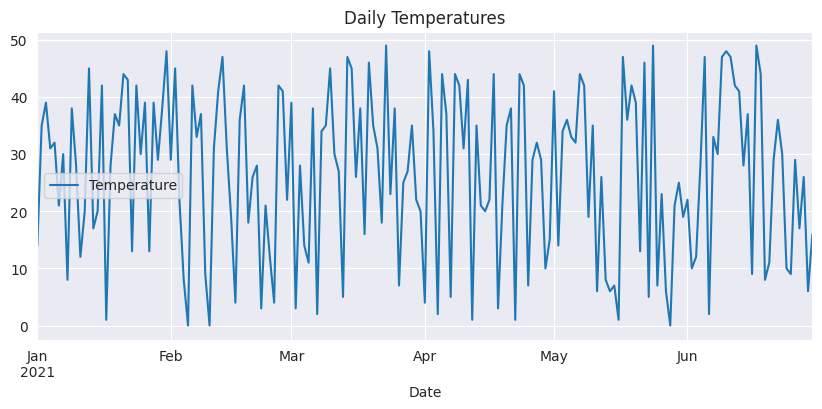

In [ ]:
# Plot the temperatures over time
date_df.plot.line(x='Date', y='Temperature', figsize=(10, 4), title='Daily Temperatures')
plt.show()

Use pd.date_range to generate an unbroken sequence of dates. Build a dataframe from it, use numpy to generate random integer temperatures spanning the length of the date array, and plot the result to simulate a real daily temperature sensor.

In [ ]:
# URL for Google stock prices (2004 → 2022) hosted on GitHub
url = "https://raw.githubusercontent.com/duochen/data-science-bootcamp/refs/heads/main/Data/google_stock_prices.csv"
# Read the CSV directly from the internet
google_stock = pd.read_csv(url)
# Convert the 'Date' column from plain text into real datetime objects
google_stock['Date'] = pd.to_datetime(google_stock['Date'])
# Use 'Date' as the DataFrame's index — required for time-series methods
google_stock.set_index('Date', inplace=True)
google_stock.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096
2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343
2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126
2004-08-24,55.675674,55.855858,51.836838,52.487488,52.487488,15247337
2004-08-25,52.532532,54.054054,51.991993,53.053055,53.053055,9188602


Load real financial data directly from a raw GitHub URL. Crucially, convert the text strings in the 'Date' column into actual pandas datetime objects using pd.to_datetime(), and then use set_index('Date') to make those dates the row labels. This unlocks time-series capabilities for plotting and resampling.

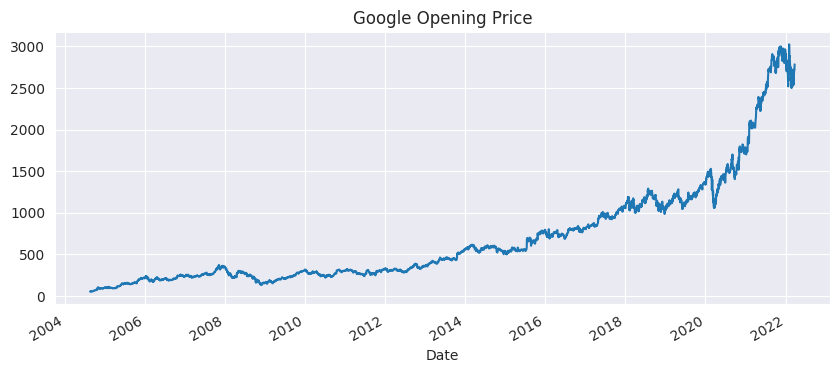

In [ ]:
# Plot the daily 'Open' price over all the years
google_stock['Open'].plot(figsize=(10, 4), title='Google Opening Price')
plt.show()

In [ ]:
# RESAMPLING = change the time granularity
# 'YE' = Year-End; .mean() gives the average price PER YEAR
yearly_open = google_stock['Open'].resample('YE').mean()
yearly_open

NameError: name 'google_stock' is not defined

Use .resample('YE') (Year-End) on the time-indexed data. Resampling works just like groupby, but specifically groups data into time blocks. Here, it takes the thousands of daily records and collapses them into a single average price per year.

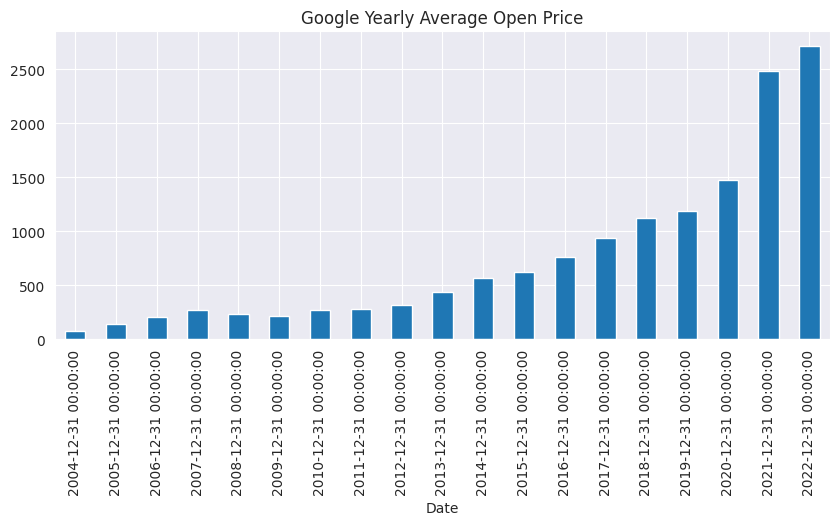

In [ ]:
# A bar chart makes the yearly trend easy to compare
yearly_open.plot(kind='bar', figsize=(10, 4), title='Google Yearly Average Open Price')
plt.show()

In [ ]:
# SHIFT moves rows up or down
# Shifting by 1 gives us the PREVIOUS day's price on each row — useful for comparisons
google_stock['Prev Open'] = google_stock['Open'].shift(1)
google_stock[['Open', 'Prev Open']].head()

,Open,Prev Open
Date,,
2004-08-19,50.050049,NaN
2004-08-20,50.555557,50.050049
2004-08-23,55.430431,50.555557
2004-08-24,55.675674,55.430431
2004-08-25,52.532532,55.675674


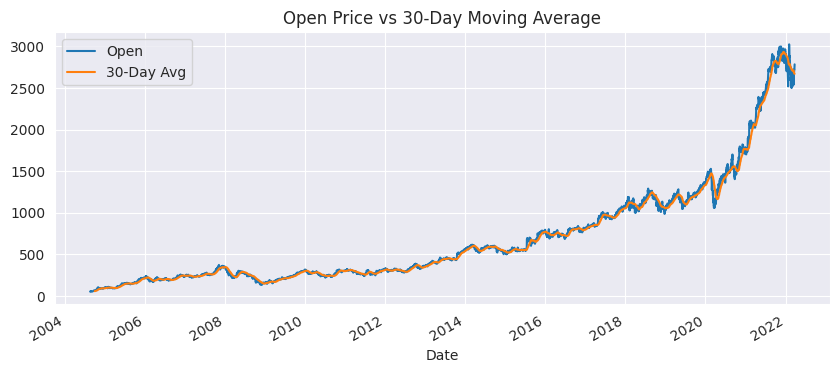

In [ ]:
# ROLLING WINDOW = compute stats over a sliding window of rows
# Here: the average of the last 30 days at each point — a '30-day moving average'
google_stock['30-Day Avg'] = google_stock['Open'].rolling(window=30).mean()
# Plot the real price and the smoothed moving average side by side
google_stock[['Open', '30-Day Avg']].plot(figsize=(10, 4), title='Open Price vs 30-Day Moving Average')
plt.show()

Use .shift(1) to push all data values down by exactly one row, allowing you to compare today's price against yesterday's price on the same row. Use .rolling(window=30).mean() to calculate the trailing 30-day average for every single row, generating a smoothed trend line that filters out daily stock volatility.

## Great job!

You now know the advanced Pandas skills that show up in almost every real data-science project:

- **groupby / agg** — answer per-group questions
- **concat / merge** — combine multiple tables
- **drop_duplicates / pd.cut** — clean & categorize data
- **pivot_table / crosstab** — reshape data
- Built-in **plots**: histogram, line, scatter, bar, box, pie, KDE
- **Time-series**: `date_range`, `resample`, `shift`, and rolling windows

These tools are what turn raw data into insights — the whole point of data science.